In [ ]:
import numpy as np
import sys
sys.path.append("..") # So we can read modules
import modules.loaddata
import modules.nuwro
import torch
from torch import nn
from dataclasses import dataclass
import pandas as pd
import os
import re
import matplotlib.pyplot as plt

In [2]:
import importlib
importlib.reload(modules.loaddata)

<module 'modules.loaddata' from 'd:\\_\\plugg\\aman26\\pythonstuff\\nrf_gen\\..\\modules\\loaddata.py'>

In [3]:
device = torch.accelerator.current_accelerator().type if torch.accelerator.is_available() else "cpu"
if device == "cuda":
    print("CUDA available")
else:
    print("⚠️ CUDA not available ⚠️")

CUDA available


In [26]:
test

,E_x,omega,R,R_low,R_high,dR_env_low,dR_env_high,dR_hw,dR_FF,R_hw12,R_hw14,R_hw16
0,0.000,0.0839,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
1,0.125,0.2089,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
2,0.250,0.3339,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
3,0.375,0.4589,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
4,0.500,0.5839,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
...,...,...,...,...,...,...,...,...,...,...,...,...
3996,499.500,499.5839,1.371460e-11,-1.128430e-10,5.062260e-10,1.371460e-11,4.925110e-10,1.265570e-10,2.721770e-18,2.532620e-10,1.482150e-13,1.371460e-11
3997,499.625,499.7089,1.358170e-11,-1.118530e-10,5.017360e-10,1.358170e-11,4.881540e-10,1.254350e-10,2.688720e-18,2.510160e-10,1.465090e-13,1.358170e-11
3998,499.750,499.8339,1.345000e-11,-1.108720e-10,4.972850e-10,1.345000e-11,4.838350e-10,1.243220e-10,2.656090e-18,2.487890e-10,1.448220e-13,1.345000e-11
3999,499.875,499.9589,1.331960e-11,-1.098990e-10,4.928730e-10,1.331960e-11,4.795530e-10,1.232190e-10,2.623880e-18,2.465810e-10,1.431550e-13,1.331960e-11


In [6]:
def mae_loss(y_pred: torch.Tensor, y_true: torch.Tensor) -> torch.Tensor:
    return torch.mean(torch.abs(y_pred - y_true))

In [35]:
def load_dat(path: str, skiplines = 3):
    data = np.loadtxt(path)
    with open(path, "r") as f:
        lines = f.readlines()
        headerline = lines[skiplines][1:]
        header = headerline.split()
    df = pd.DataFrame(data, columns=header)
    return df

In [ ]:
# CURVETYPE_AVG = 0
# CURVETYPE_MIN = 1
# CURVETYPE_MAX = 2

class DataManager():
    def __init__(self, source_path: str = "./source_nrfs/"):

        # Find data files
        filenames = os.listdir(source_path)
        q_vals = []
        response_names = []
        names = []
        for filename in filenames:
            match = re.match(r"^([A-z]+)_([A-z]+)_q(\d+)\.dat$", filename)
            if match:
                name = match.group(1)
                response_name = match.group(2)
                q_val = int(match.group(3))
                if not name in names:
                    names.append(name)
                if not response_name in response_names:
                    response_names.append(response_name)
                if not q_val in q_vals:
                    q_vals.append(q_val)

        if len(names) != 1:
            raise ValueError(f"Multiple names found in source path: {names}")
        

        # Load data from files
        omega_vals = []
        responses = []

        for q in q_vals:
            omega_vals_for_q = None
            responses_for_q = []
            for response_name in response_names:
                filename = f"{names[0]}_{response_name}_q{q}.dat"
                df = load_dat(os.path.join(source_path, filename))
                if omega_vals_for_q is None:
                    omega_vals_for_q = df["omega"].values
                else:
                    if not np.isclose(df["omega"].values, omega_vals_for_q).all():
                        raise ValueError(f"Omega values do not match for {filename}")
                response = df["R"].values
                responses_for_q.append(response)

            responses.append(responses_for_q)
            omega_vals.append(omega_vals_for_q)

        responses = np.array(responses)     # shape[n_q, n_nrfs, n_omega]
        q_vals = np.array(q_vals)           # shape [n_q]
        omega_vals = np.array(omega_vals)   # shape [n_q, n_omega]

        # Flatten data to a DataFrame
        q_vals_flat = []
        omega_vals_flat = []
        nrfs_flat = []
        for q_idx, q in enumerate(q_vals):
            for w_idx, w in enumerate(omega_vals[q_idx]):
                q_vals_flat.append(q)
                omega_vals_flat.append(w)
                nrfs_flat.append(responses[q_idx, :, w_idx])

        df = pd.DataFrame({
            "q": q_vals_flat,
            "omega": omega_vals_flat
        })

        for i, response_name in enumerate(response_names):
            df[response_name] = [nrf[i] for nrf in nrfs_flat]
        
        self.df = df
        self.response_names = response_names

        self.nrf_count = len(response_names)

    def configure_data(self, q_to_test=[]):
        X_train = []
        Y_train = []
        
        X_test = []
        Y_test = []

        # train_mask = self.df["q"] != q_to_test
        test_mask = self.df["q"].isin(q_to_test)
        train_mask = ~test_mask

        X_train = self.df[train_mask][["omega", "q"]].values
        Y_train = self.df[train_mask][self.response_names].values

        X_test = self.df[test_mask][["omega", "q"]].values
        Y_test = self.df[test_mask][self.response_names].values

        X_train = np.array(X_train)
        Y_train = np.array(Y_train)
        X_test = np.array(X_test)
        Y_test = np.array(Y_test)

        print("TrainX Shape:", X_train.shape)
        print("TrainY Shape:", Y_train.shape)
        print("TestX Shape: ", X_test.shape)
        print("TestY Shape: ", Y_test.shape)

        X_train = torch.tensor(X_train, dtype=torch.float32).to(device)
        Y_train = torch.tensor(Y_train, dtype=torch.float32).to(device)
        
        X_test = torch.tensor(X_test, dtype=torch.float32).to(device)
        Y_test = torch.tensor(Y_test, dtype=torch.float32).to(device)

        # Normalized data
        self.X_mean = X_train.mean(dim=0, keepdim=True)
        self.X_std = X_train.std(dim=0, keepdim=True)
        self.Y_mean = Y_train.mean(dim=0, keepdim=True)
        self.Y_std = Y_train.std(dim=0, keepdim=True)

        X_train = self.x_to_normalised(X_train)
        Y_train = self.y_to_normalised(Y_train)
        
        X_test = self.x_to_normalised(X_test)
        Y_test = self.y_to_normalised(Y_test)


        self.X_train_GPU = X_train.to(device)
        self.Y_train_GPU = Y_train.to(device)
        self.X_test_GPU = X_test.to(device)
        self.Y_test_GPU = Y_test.to(device)
    
    def x_to_normalised(self, X):
        X = (X - self.X_mean) / self.X_std 
        return X
    def y_to_normalised(self, Y):
        Y = (Y - self.Y_mean) / self.Y_std
        return Y

    def x_from_normalized(self, X):
        X = X * self.X_std + self.X_mean
        return X
    def y_from_normalized(self, Y):
        Y = Y * self.Y_std + self.Y_mean
        return Y
    

In [69]:
dm = DataManager("../data/O16_responses/O16_inversions/EM")
dm.configure_data([75])

TrainX Shape: (32008, 2)
TrainY Shape: (32008, 2)
TestX Shape:  (0, 2)
TestY Shape:  (0, 2)


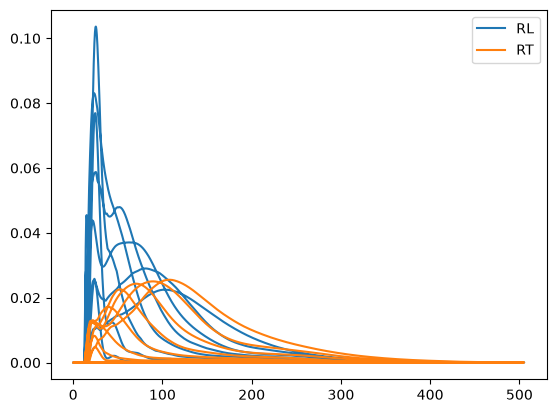

In [110]:
mask = dm.df["q"] != 30000
for name in dm.response_names:
    plt.plot(dm.df[mask]["omega"], dm.df[mask][name], label=name)
plt.legend()
# plt.plot(dm.df[mask]["omega"], dm.df[mask]["Rxx"], label="R00")

In [52]:
def mae_loss(y_pred: torch.Tensor, y_true: torch.Tensor) -> torch.Tensor:
    return torch.mean(torch.abs(y_pred - y_true))


@dataclass
class Params:
    layers: list[int]
    activation: nn.Module
    loss_fn: callable
    base_lr: float
    weight_decay: float
params = Params(
    layers=[128,128,128,128,128,128],
    activation=nn.GELU(),
    loss_fn=mae_loss,
    base_lr=1e-3,
    weight_decay=1e-4,
)

In [103]:
class AbInitioNN(nn.Module):
    def __init__(self, nnParams, dataManager: DataManager):
        super().__init__()
        self.dataManager = dataManager
        self.nnParams = nnParams

        self.flatten = nn.Flatten()
        
        self.layer_stack = nn.Sequential()
        self.layer_stack.add_module("input_layer", nn.Linear(2, nnParams.layers[0]))
        self.layer_stack.add_module(f"activation_0", nnParams.activation)
        for i, layer_size in enumerate(nnParams.layers[1:], start=1):
            self.layer_stack.add_module(f"layer_{i}", nn.Linear(nnParams.layers[i-1], layer_size))
            self.layer_stack.add_module(f"activation_{i}", nnParams.activation)
        self.layer_stack.add_module("output_layer", nn.Linear(nnParams.layers[-1], dataManager.nrf_count))
        
        self.to(device)
        

        self.loss_fn = nnParams.loss_fn
        self.optimizer = torch.optim.Adam(self.parameters(), lr=nnParams.base_lr, weight_decay=nnParams.weight_decay)

        self.train_loss_history = []
        self.test_loss_history = []


    def forward(self, x):
        x = self.flatten(x)
        logits = self.layer_stack(x)
        return logits
    
    def train_single_iteration(self, X, y, log: bool): # Only run this when the setup in train_for has been done
        pred = self(X)
        loss = self.loss_fn(pred, y)
        loss.backward()
        self.optimizer.step()
        self.optimizer.zero_grad()

        loss = loss.item()
        self.train_loss_history.append(loss)
        if log:
            print(f"loss: {loss:>7f} ")
    
    def train_for(self, steps: int, log: bool = True):
        '''
        Train the network on the data provided by the DataManager for the given number of steps.
        - steps: Number of epochs to run for
        - log: Whether to print info during training. Disable to clear up the output
        '''
        self.train()
        # X, y = next(iter(self.dataManager.train_dataloader)) # Everything fits in one batch, saves on data transfer to GPU
        # X, y = X.to(device), y.to(device)
        for t in range(steps):
            if log:
                print(f"Epoch {t+1}\n-------------------------------")
            self.train_single_iteration(self.dataManager.X_train_GPU, self.dataManager.Y_train_GPU, log)
        if log:
            print("Done!")
    
    def test(self, log: bool = True):
        self.eval()
        # X, y = next(iter(self.dataManager.test_dataloader))
        # X, y = X.to(device), y.to(device)
        loss = 0
        with torch.no_grad():
            pred = self(self.dataManager.X_test_GPU)
            loss = self.loss_fn(pred, self.dataManager.Y_test_GPU).item()
            self.test_loss_history.append(loss)
        if log:
            print(f"Test loss: {loss:>8f} \n")
        return loss
    
    def make_transformed_prediction(self, qvals, wvals):
        
        inputs = torch.tensor([[w, q] for w, q in zip(wvals, qvals)], dtype=torch.float32).to(device)
        inputs =self.dataManager.x_to_normalised(inputs)
        with torch.no_grad():
            preds = self(inputs)
            preds = self.dataManager.y_from_normalized(preds).cpu().numpy()
        return preds

In [104]:
net = AbInitioNN(params, dm)
net.train_for(steps=1000, log=True)

Epoch 1
-------------------------------
loss: 0.673720 
Epoch 2
-------------------------------
loss: 0.664908 
Epoch 3
-------------------------------
loss: 0.655946 
Epoch 4
-------------------------------
loss: 0.646388 
Epoch 5
-------------------------------
loss: 0.635735 
Epoch 6
-------------------------------
loss: 0.623329 
Epoch 7
-------------------------------
loss: 0.608232 
Epoch 8
-------------------------------
loss: 0.589108 
Epoch 9
-------------------------------
loss: 0.564137 
Epoch 10
-------------------------------
loss: 0.530914 
Epoch 11
-------------------------------
loss: 0.486698 
Epoch 12
-------------------------------
loss: 0.448564 
Epoch 13
-------------------------------
loss: 0.488070 
Epoch 14
-------------------------------
loss: 0.489280 
Epoch 15
-------------------------------
loss: 0.459439 
Epoch 16
-------------------------------
loss: 0.435757 
Epoch 17
-------------------------------
loss: 0.436580 
Epoch 18
-------------------------------

Text(0, 0.5, 'Loss')

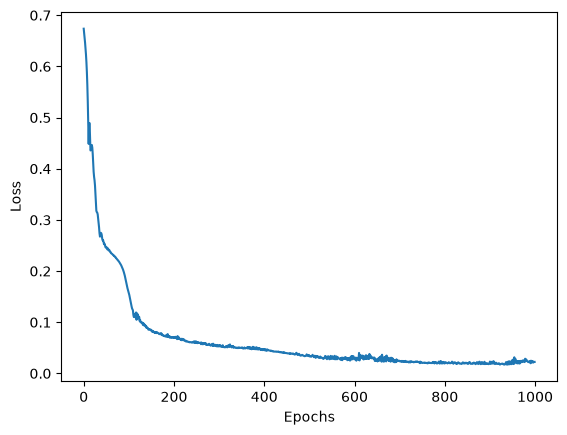

In [106]:
plt.plot(net.train_loss_history, label="Train Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")

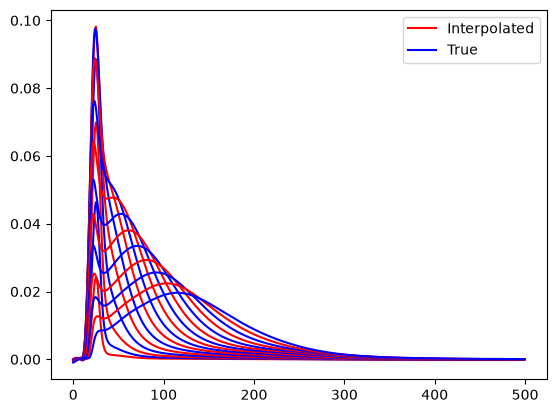

In [290]:
a = False
b = False
for q in np.arange(50, 450, 25):
    label = None
    col = "red"
    if q % 50 == 25:
        col = "blue"
        if not a:
            label = "True"
            a = True
    else:
        if not b:
            label = "Interpolated"
            b = True
    preds = net.make_transformed_prediction([q] * 500, np.arange(0, 500, 1))
    plt.plot(np.arange(0, 500, 1), preds[:, 0], label=label, color=col)
plt.legend()


array([   0.,    4.,    8., ..., 1188., 1192., 1196.], shape=(90000,))

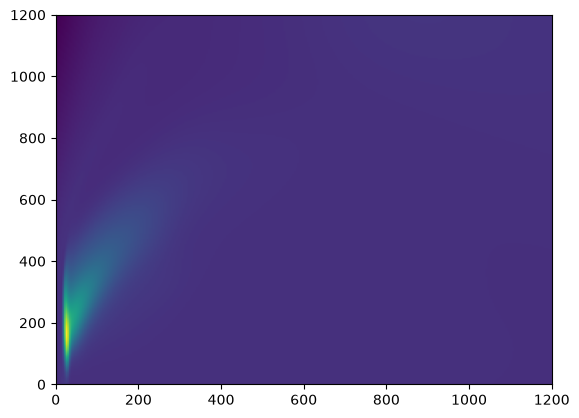

In [109]:
grid_spacing = 4.0
grid_steps = 300

grid = np.arange(0, grid_steps * grid_spacing, grid_spacing)
w, q = np.meshgrid(grid, grid)

pred = net.make_transformed_prediction(q.flatten(), w.flatten())

plt.imshow(pred[:, 0].reshape(grid_steps, grid_steps), extent=(0, grid_steps * grid_spacing, 0, grid_steps * grid_spacing), origin='lower', aspect='auto')

res = ""
for i, nrf in enumerate(dm.response_names):
    res += modules.nuwro.ListToCppArray(pred[:, i], f'nrf_{nrf}')
    # res += "\n\n"
res += "static double *nrfs[] = {"
for nrf in dm.response_names:
    res += f"nrf_{nrf}, "
res = res[:-2]
res += "};"

with open("nrf_export.cpp", "w") as f:
    f.write(res)

w.flatten()

Text(0.5, 0.98, 'q=400 MeV, $\\epsilon$=600 MeV')

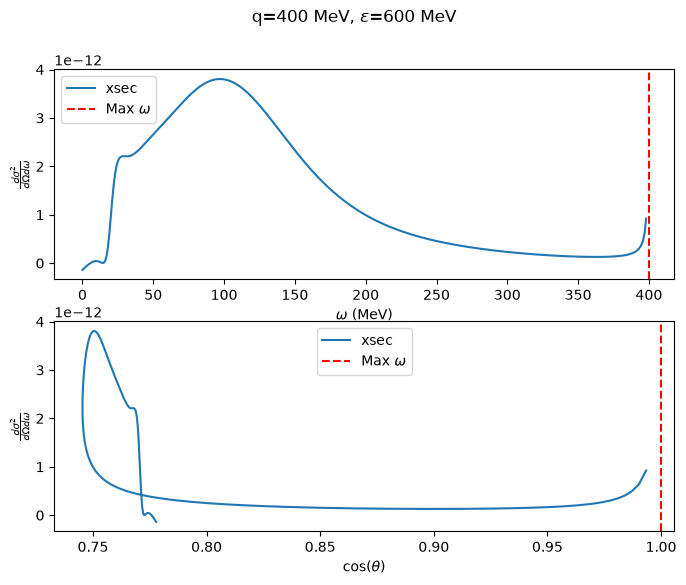

In [296]:
q = 400
eps = 600

maxw = np.minimum(q, 2 * eps - q)

w = np.arange(0, maxw-1, 1)
eps_prim = eps - w

Q_sq = q**2 - w**2
def wq_to_theta(q, eps, w):
    return np.arccos((q**2 - eps**2 - (eps-w)**2) / (-2 * eps * (eps-w)))
theta = wq_to_theta(q, eps, w)

# q^2 - eps^2 - (eps-w)^2 = q^2 - 2eps^2 + 2eps w - w^2 = 1
# w^2 - w 2 eps + 2 eps^2 - q^2 - 1 = 0
# -> w = -eps +/- sqrt(eps^2 - 2 eps^2 + q^2 + 1) = -eps +/- sqrt(q^2 - eps^2 + 1)

upper = 2 * eps + q
lower = 2 * eps - q

upper2 = q

# plt.axvline(lower, color="red", linestyle="--")
# plt.axvline(upper, color="green", linestyle="--")

# plt.axvline(upper2, color="blue", linestyle="--")

fine_structure= 1/137.036

xsec_mott = fine_structure**2 * np.cos(theta)**2 / (4 * eps**2 * np.sin(theta)**4)
vRL = (Q_sq/q**2)**2
vRT = (Q_sq/(2*q**2) + np.tan(theta/2)**2)

nrfs = net.make_transformed_prediction([q] * len(w), w)

xsec = vRL * nrfs[:, 0] + vRT * nrfs[:, 1]

# xsec = 1
xsec *= xsec_mott

fig, axs = plt.subplots(2, 1, figsize=(8, 6))

ax1 = axs[0]
ax2 = axs[1]

ax1.plot(w, xsec, label="xsec")
ax1.axvline(maxw, color="red", linestyle="--", label="Max $\\omega$")
# plt.xlim(0, q + 100)
# plt.plot(w,theta * 1e53)
ax1.set_xlabel("$\\omega$ (MeV)")
ax1.set_ylabel("$\\frac{d\\sigma^2}{d\\Omega d \\omega}$")
ax1.legend()
# ax1.set_ylim(-1e14, 1e-13)

ax2.plot(np.cos(theta), xsec, label="xsec")
ax2.axvline(np.cos(wq_to_theta(q, eps, maxw)), color="red", linestyle="--", label="Max $\\omega$")
ax2.set_xlabel("$\\cos(\\theta)$")
ax2.set_ylabel("$\\frac{d\\sigma^2}{d\\Omega d \\omega}$")
ax2.legend()
# ax2.set_ylim(-1e-13)

plt.suptitle(f"q={q} MeV, $\\epsilon$={eps} MeV")